In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import chi2

portfolio_df = pd.read_csv(
    "../data/processed/portfolio_returns.csv",
    index_col=0,
    parse_dates=True
)

portfolio_returns = portfolio_df["PortfolioReturn"]

portfolio_returns.head()

Date
2021-01-05    0.002310
2021-01-06   -0.008148
2021-01-07    0.007074
2021-01-08   -0.002222
2021-01-11   -0.006314
Name: PortfolioReturn, dtype: float64

In [2]:
window = 250

rolling_var_95 = (
    portfolio_returns
    .rolling(window)
    .quantile(0.05)
    .shift(1)
)

rolling_var_99 = (
    portfolio_returns
    .rolling(window)
    .quantile(0.01)
    .shift(1)
)

In [3]:
backtest = pd.DataFrame({
    "Return": portfolio_returns,
    "VaR_95": rolling_var_95,
    "VaR_99": rolling_var_99
}).dropna()

backtest.head()

,Return,VaR_95,VaR_99
Date,,,
2021-12-31,-0.000799,-0.008292,-0.014765
2022-01-03,-0.004780,-0.008292,-0.014765
2022-01-04,-0.003255,-0.008292,-0.014765
2022-01-05,-0.013878,-0.008292,-0.014765
2022-01-06,-0.001347,-0.008384,-0.014775


In [4]:
backtest["Exception_95"] = (
    backtest["Return"] < backtest["VaR_95"]
)

backtest["Exception_99"] = (
    backtest["Return"] < backtest["VaR_99"]
)

In [5]:
n_days = len(backtest)

exceptions_95 = backtest["Exception_95"].sum()
exceptions_99 = backtest["Exception_99"].sum()

expected_95 = n_days * 0.05
expected_99 = n_days * 0.01

print("Backtesting days:", n_days)

print("\n95% VaR")
print("Actual exceptions:", exceptions_95)
print("Expected exceptions:", expected_95)
print("Exception rate:", exceptions_95 / n_days)

print("\n99% VaR")
print("Actual exceptions:", exceptions_99)
print("Expected exceptions:", expected_99)
print("Exception rate:", exceptions_99 / n_days)

Backtesting days: 1217

95% VaR
Actual exceptions: 72
Expected exceptions: 60.85
Exception rate: 0.05916187345932621

99% VaR
Actual exceptions: 18
Expected exceptions: 12.17
Exception rate: 0.014790468364831553


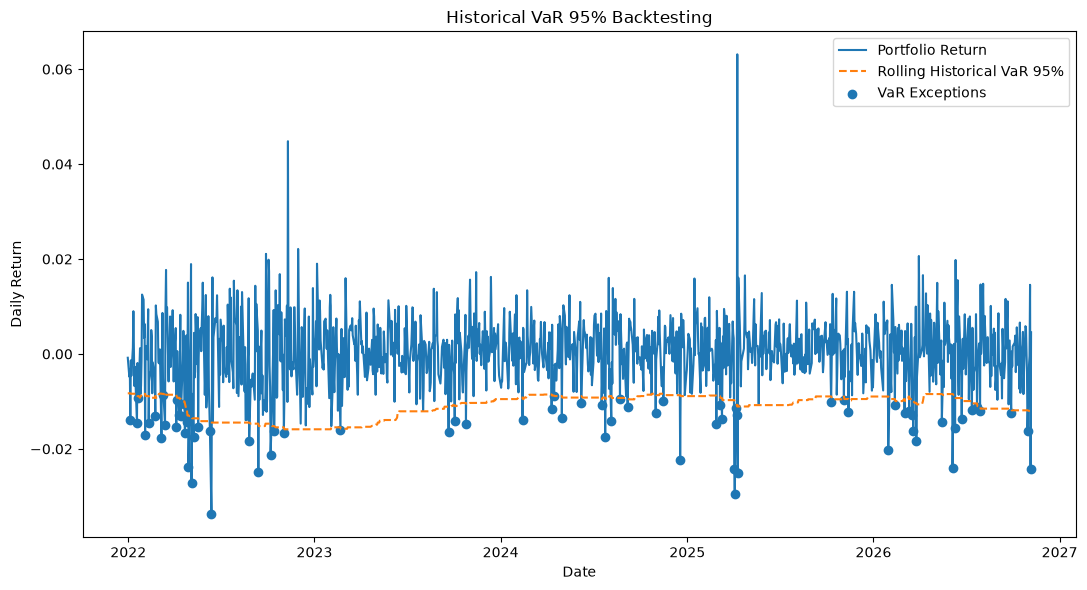

In [6]:
plt.figure(figsize=(11, 6))

plt.plot(
    backtest.index,
    backtest["Return"],
    label="Portfolio Return"
)

plt.plot(
    backtest.index,
    backtest["VaR_95"],
    linestyle="--",
    label="Rolling Historical VaR 95%"
)

exceptions = backtest[
    backtest["Exception_95"]
]

plt.scatter(
    exceptions.index,
    exceptions["Return"],
    label="VaR Exceptions"
)

plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.title("Historical VaR 95% Backtesting")

plt.legend()
plt.tight_layout()

plt.savefig(
    "../reports/figures/var_backtesting_95.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
def kupiec_test(n, x, alpha):

    if x == 0 or x == n:
        return np.nan, np.nan

    p_hat = x / n

    log_likelihood_null = (
        (n - x) * np.log(1 - alpha)
        + x * np.log(alpha)
    )

    log_likelihood_alt = (
        (n - x) * np.log(1 - p_hat)
        + x * np.log(p_hat)
    )

    lr_stat = -2 * (
        log_likelihood_null
        - log_likelihood_alt
    )

    p_value = 1 - chi2.cdf(
        lr_stat,
        df=1
    )

    return lr_stat, p_value

In [8]:
kupiec_95_stat, kupiec_95_p = kupiec_test(
    n_days,
    exceptions_95,
    0.05
)

print("Kupiec 95% LR:", kupiec_95_stat)
print("Kupiec 95% p-value:", kupiec_95_p)

Kupiec 95% LR: 2.0364979592349073
Kupiec 95% p-value: 0.15356283154756656


In [9]:
kupiec_99_stat, kupiec_99_p = kupiec_test(
    n_days,
    exceptions_99,
    0.01
)

print("Kupiec 99% LR:", kupiec_99_stat)
print("Kupiec 99% p-value:", kupiec_99_p)

Kupiec 99% LR: 2.4585787808677253
Kupiec 99% p-value: 0.11688449753943475


In [10]:
backtesting_summary = pd.DataFrame({
    "Confidence": ["95%", "99%"],
    "Backtest_Days": [
        n_days,
        n_days
    ],
    "Expected_Exceptions": [
        expected_95,
        expected_99
    ],
    "Actual_Exceptions": [
        exceptions_95,
        exceptions_99
    ],
    "Exception_Rate": [
        exceptions_95 / n_days,
        exceptions_99 / n_days
    ],
    "Kupiec_LR": [
        kupiec_95_stat,
        kupiec_99_stat
    ],
    "Kupiec_p_value": [
        kupiec_95_p,
        kupiec_99_p
    ]
})

backtesting_summary

,Confidence,Backtest_Days,Expected_Exceptions,Actual_Exceptions,Exception_Rate,Kupiec_LR,Kupiec_p_value
0,95%,1217,60.85,72,0.059162,2.036498,0.153563
1,99%,1217,12.17,18,0.014790,2.458579,0.116884


## Backtesting Results

The rolling Historical VaR model was evaluated over 1,217 out-of-sample observations using a 250-day estimation window.

At the 95% confidence level, 72 exceptions were observed compared with approximately 61 expected exceptions, corresponding to an exception rate of 5.92%.

At the 99% confidence level, 18 exceptions were observed compared with approximately 12 expected exceptions, corresponding to an exception rate of 1.48%.

Although observed exception rates were moderately higher than their theoretical levels, the Kupiec unconditional coverage test produced p-values above 5% for both confidence levels.

Therefore, the null hypothesis of correct unconditional coverage was not rejected at the 5% significance level.

The results suggest that the Historical VaR model provides reasonable coverage, although the elevated exception rates indicate some tendency to underestimate tail risk.